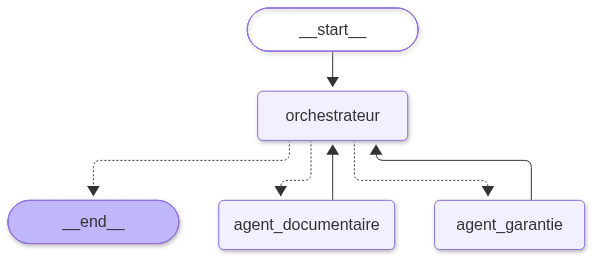

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from app.sav_orchestrateur import graph, traiter_demande
from IPython.display import Image, display, Markdown

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    print(graph.get_graph().draw_mermaid())

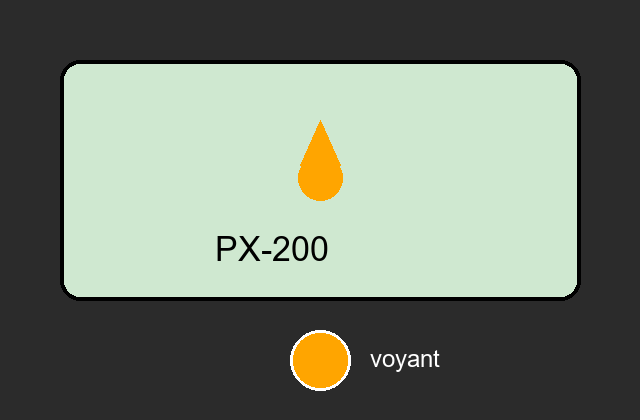

In [2]:
display(Image(filename=str(ROOT / "data" / "sav" / "images" / "img_px200_01.png"), width=320))

In [3]:
r = await traiter_demande(
    "Mon imprimante PX-200 affiche un voyant clignotant. Que signifie le pictogramme sur la photo jointe ?",
    image_ref="img_px200_01",
)
print("\nCatégorie :", r["categorie"], "| Agent :", r["agent"])
display(Markdown(r["reponse_finale"]))

🎯 [orchestrateur] catégorie = documentation -> agent_documentaire (Le client demande l'interprétation d'un pictogramme associé à un voyant clignotant sur son imprimante PX-200. Cela relève directement de la catégorie « documentation » (pictogramme) et non de la garantie (qui concerne la couverture ou le numéro de série).)
📚 [agent_documentaire] appel MCP rag_multimodal({'question': 'Mon imprimante PX-200 affiche un voyant clignotant. Que signifie le pictogramme sur la photo jointe ?', 'image_ref': 'img_px200_01'})
🎯 [orchestrateur] réponse finale disponible -> fin

Catégorie : documentation | Agent : agent_documentaire


Le pictogramme en forme de goutte orange avec le voyant orange clignotant indique : **le niveau d'encre d'une cartouche est bas**. L'impression reste possible mais la cartouche doit être remplacée rapidement [Manuel PX-200, section 2. Voyant d'état et pictogrammes]. Cette information est également confirmée par [Figure 1 — Pictogrammes du panneau PX-200].

In [4]:
r = await traiter_demande("Est-ce que mon imprimante est encore sous garantie ? Son numéro de série est PX200-0042.")
print("\nCatégorie :", r["categorie"], "| Agent :", r["agent"])
display(Markdown(r["reponse_finale"]))

🎯 [orchestrateur] catégorie = garantie -> agent_garantie (Le client demande si son appareil est encore couvert par la garantie et fournit un numéro de série, ce qui relève directement de la catégorie « garantie » (savoir si l'appareil est encore couvert, numéro de série).)
🛡️ [agent_garantie] appel local consulter_garantie({'numero_serie': 'PX200-0042'})
🎯 [orchestrateur] réponse finale disponible -> fin

Catégorie : garantie | Agent : agent_garantie


Oui, votre imprimante est encore sous garantie jusqu'au 15 juin 2027.

In [5]:
for question in [
    "Ma PX200-0007 est-elle toujours couverte par la garantie ?",                  # garantie expirée
    "Le voyant de mon imprimante est rouge fixe avec une feuille barrée, que faire ?",  # bourrage, sans photo
]:
    print("\n" + "=" * 80)
    r = await traiter_demande(question)
    print("Catégorie :", r["categorie"], "| Agent :", r["agent"])
    display(Markdown(r["reponse_finale"]))


🎯 [orchestrateur] catégorie = garantie -> agent_garantie (La demande porte sur la vérification de la couverture de la garantie en utilisant le numéro de série fourni (PX200-0007), ce qui correspond à la catégorie « garantie » (savoir si l'appareil est encore couvert, numéro de série).)
🛡️ [agent_garantie] appel local consulter_garantie({'numero_serie': 'PX200-0007'})
🎯 [orchestrateur] réponse finale disponible -> fin
Catégorie : garantie | Agent : agent_garantie


Votre appareil PX200-0007 n'est plus couvert par la garantie. La garantie a expiré le 10 janvier 2025. La date actuelle est le 28 novembre 2026.


🎯 [orchestrateur] catégorie = documentation -> agent_documentaire (La description du voyant rouge fixe avec une feuille barrée correspond à un symptôme ou un code d'erreur spécifique à l'appareil. Cela relève de la documentation (panne, voyant, pictogramme) car le client demande une interprétation ou une solution pour ce symptôme, et non une vérification de la couverture de garantie ou du numéro de série.)
📚 [agent_documentaire] appel MCP rag_multimodal({'question': 'Le voyant de mon imprimante est rouge fixe avec une feuille barrée, que faire ?'})
🎯 [orchestrateur] réponse finale disponible -> fin
Catégorie : documentation | Agent : agent_documentaire


Le voyant rouge fixe avec une feuille barrée indique un **bourrage papier** (section 2). Pour le résoudre :  
1. Éteignez l'imprimante.  
2. Retirez le bac arrière et tirez doucement la feuille coincée vers le haut à deux mains (voir [Figure 3]).  
3. Vérifiez qu'aucun morceau de papier ne reste dans l'imprimante.  
4. Remettez le bac puis rallumez l'imprimante.  

[Manuel PX-200, section 5] et [Figure 3].